# Corporate Rating Prediction & Migration Matrices

Many counterparties have no agency rating, yet every credit system needs one to price, limit and provision them. A model that reads financial statements and places a company on the agency scale fills that gap, and migration matrices then say how those ratings tend to move. This notebook builds both and is honest about how well they really work on companies the model has never seen.

**What it does.** It predicts the agency rating of U.S. listed companies from their financial ratios with four models, and shows how much a naive random split overstates accuracy when the same company appears many times. It also measures how far the agencies disagree with each other.

Finally, it estimates one-year rating migration matrices with the cohort and the continuous-time (generator) methods, after cleaning the data for implausible rating reversals.

**Data.** 7,805 ratings of 678 companies by S&P, Moody's, Fitch, Egan-Jones and others, 2010–2016, each with 16 financial ratios from the latest filing (Kaggle `kirtandelwadia/corporate-credit-rating-with-financial-ratios`, built from SEC filings).

**Methods.** Ordinal logit (proportional odds), multinomial logit, an SVM with an RBF kernel and LightGBM, validated with random, company-grouped and out-of-time splits. The scores are exact and within-one-grade accuracy, rank correlation and investment-grade AUC.

Agency disagreement is measured as notch differences between pairs of agencies. Migration matrices use the cohort method and an Aalen–Johansen-style generator with the matrix exponential.

**Key output.** Prediction accuracy under honest validation, the ratios that drive ratings, the size of agency disagreement, and migration matrices with their data-quality caveats.

## 1. Why ratings models and migration matrices

A credit-risk officer uses ratings in two ways:

- **Shadow ratings.** Many counterparties, especially private companies and sub-sovereigns, have no agency rating. An internal model that maps financial statements to the agency scale gives them one, and puts rated and unrated names on the same PD masterscale.
- **Migration matrices** say how ratings move over a year. They drive CreditMetrics-style portfolio models, IFRS 9 staging (a significant increase in credit risk is often defined as a number of notches of downgrade), lifetime PDs ($P^n$ for $n$ years) and the expected downgrade loss of a bond book.

**Methods.** A rating is an *ordered* category, so the natural model is the **ordinal logit**: $P(R\le k\mid x)=\Lambda(\theta_k-x'\beta)$, one set of slopes and $K-1$ cut points. The multinomial logit, the SVM and LightGBM ignore the ordering but are more flexible.

For migrations, the **cohort method** counts year-end-to-year-end transitions, $\hat p_{ij}=N_{ij}/N_i$, and misses moves that reverse within the year. The **duration (generator) method** uses every rating change and the time spent in each grade, $\hat\lambda_{ij}=N_{ij}/\int Y_i(t)\,dt$, and recovers the one-year matrix as $P=\exp(\Lambda)$. It gives positive probabilities to multi-notch moves and defaults even when none were observed directly.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import statsmodels.api as sm
from scipy import stats
from scipy.linalg import expm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from statsmodels.miscmodels.ordinal_model import OrderedModel

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 3
KAGGLE_DATASET, RATINGS_FILE = (
    "kirtandelwadia/corporate-credit-rating-with-financial-ratios",
    "corporateCreditRatingWithFinancialRatios.csv",
)
NOTCHES = [
    "AAA",
    "AA+",
    "AA",
    "AA-",
    "A+",
    "A",
    "A-",
    "BBB+",
    "BBB",
    "BBB-",
    "BB+",
    "BB",
    "BB-",
    "B+",
    "B",
    "B-",
    "CCC+",
    "CCC",
    "CCC-",
    "CC+",
    "CC",
    "C",
    "D",
]
LETTER = {
    "AAA": "AAA",
    "AA+": "AA",
    "AA": "AA",
    "AA-": "AA",
    "A+": "A",
    "A": "A",
    "A-": "A",
    "BBB+": "BBB",
    "BBB": "BBB",
    "BBB-": "BBB",
    "BB+": "BB",
    "BB": "BB",
    "BB-": "BB",
    "B+": "B",
    "B": "B",
    "B-": "B",
    "CCC+": "CCC/C",
    "CCC": "CCC/C",
    "CCC-": "CCC/C",
    "CC+": "CCC/C",
    "CC": "CCC/C",
    "C": "CCC/C",
    "D": "D",
}
GRADES = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC/C", "D"]
# modelling target: six ordered classes
CLASSES = ["AAA/AA", "A", "BBB", "BB", "B", "CCC and below"]
TO_CLASS = {
    "AAA": 0,
    "AA": 0,
    "A": 1,
    "BBB": 2,
    "BB": 3,
    "B": 4,
    "CCC/C": 5,
    "D": 5,
}
MAJOR_AGENCIES = [
    "Standard & Poor's Ratings Services",
    "Moody's Investors Service",
    "Fitch Ratings",
]

print(
    f"statsmodels {sm.__version__} · lightgbm {lgb.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

statsmodels 0.15.0 · lightgbm 4.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- Kaggle downloads
# The kaggle package authenticates with KAGGLE_API_TOKEN (read from .env above)
# or with
# ~/.kaggle/access_token / ~/.kaggle/kaggle.json. It is imported here, after
# load_dotenv, on purpose.
import zipfile


def kaggle_api():
    from kaggle.api.kaggle_api_extended import KaggleApi

    api = KaggleApi()
    api.authenticate()
    return api


def kaggle_file(ref, filename, competition=False):
    """
    Download one file of a Kaggle dataset or competition into data/ (once) and
    return its local path.
    """
    target = DATA_DIR / filename
    if target.exists():
        return target
    api = kaggle_api()
    if competition:
        api.competition_download_file(ref, filename, path=DATA_DIR, quiet=True)
    else:
        api.dataset_download_file(ref, filename, path=DATA_DIR, quiet=True)
    zipped = DATA_DIR / f"{Path(filename).name}.zip"
    # large files arrive zipped
    if zipped.exists():
        with zipfile.ZipFile(zipped) as z:
            z.extractall(DATA_DIR)
        zipped.unlink()
    if not target.exists():
        raise FileNotFoundError(
            f"{filename} not found after download from {ref}"
        )
    return target

## 3. Data

Each row is a rating action with the company's ratios from its most recent financial statements (SEC filings). The ratings are on the S&P notch scale for all agencies. Ratios have extreme values (negative equity makes ROE and debt/equity explode), so every ratio is winsorised at the 1st and 99th percentiles.

In [3]:
raw = pd.read_csv(
    kaggle_file(KAGGLE_DATASET, RATINGS_FILE), parse_dates=["Rating Date"]
)
r = raw[raw["Rating"].isin(NOTCHES)].copy()
r = r.drop_duplicates(["Ticker", "Rating Agency", "Rating Date"])
r["notch"] = r["Rating"].map({n: i for i, n in enumerate(NOTCHES)})
r["grade"] = r["Rating"].map(LETTER)
r["cls"] = r["grade"].map(TO_CLASS)
RATIOS = [
    "Current Ratio",
    "Long-term Debt / Capital",
    "Debt/Equity Ratio",
    "Gross Margin",
    "Operating Margin",
    "EBIT Margin",
    "EBITDA Margin",
    "Pre-Tax Profit Margin",
    "Net Profit Margin",
    "Asset Turnover",
    "ROE - Return On Equity",
    "Return On Tangible Equity",
    "ROA - Return On Assets",
    "ROI - Return On Investment",
    "Operating Cash Flow Per Share",
    "Free Cash Flow Per Share",
]
for c in RATIOS:
    lo, hi = r[c].quantile([0.01, 0.99])
    r[c] = r[c].clip(lo, hi)
r["year"] = r["Rating Date"].dt.year
print(
    f"{len(r):,} ratings · {r['Ticker'].nunique():,} companies ·"
    f" {r['Rating Agency'].nunique()} agencies ·"
    f" {r['Rating Date'].min():%Y-%m} → {r['Rating Date'].max():%Y-%m}"
)
display(
    pd.crosstab(r["Rating Agency"], r["grade"]).reindex(
        columns=GRADES, fill_value=0
    )
)
r.groupby("grade")[[
    "Long-term Debt / Capital",
    "EBITDA Margin",
    "ROA - Return On Assets",
    "Current Ratio",
]].median().reindex(GRADES).round(2)

7,804 ratings · 678 companies · 7 agencies · 2010-04 → 2016-12


grade,AAA,AA,A,BBB,BB,B,CCC/C,D
Rating Agency,,,,,,,,
DBRS,0,1,11,13,1,0,0,0
Egan-Jones Ratings Company,5,304,1071,789,401,210,44,2
Fitch Ratings,0,11,100,227,79,36,24,0
HR Ratings de Mexico S.A. de C.V.,2,3,0,0,0,0,0,0
"Japan Credit Rating Agency,Ltd.",0,8,14,0,0,0,0,0
Moody's Investors Service,7,39,264,562,339,335,89,1
Standard & Poor's Ratings Services,76,146,576,869,605,439,99,2


,Long-term Debt / Capital,EBITDA Margin,ROA - Return On Assets,Current Ratio
grade,,,,
AAA,0.14,25.07,9.64,1.78
AA,0.26,22.54,8.51,1.59
A,0.38,22.09,6.39,1.33
BBB,0.42,18.44,4.90,1.45
BB,0.47,15.26,3.76,1.63
B,0.56,11.96,1.68,1.69
CCC/C,0.69,8.60,-0.26,1.69
D,0.18,4.86,-5.27,1.49


## 4. Rating prediction: three ways to split the data

The same company is rated many times (by several agencies, in several years) with nearly identical ratios. A **random split** puts the same company in both train and test, so the model can recognise the company instead of learning the mapping from ratios to ratings. Two honest alternatives:

- **company-grouped split:** 25% of companies are held out entirely;
- **out-of-time split:** train on 2010–2014, test on 2015–2016 (companies can recur, but later ratings are predicted from earlier ones).

Features: the 16 ratios plus sector dummies. The linear models and the SVM use standardised ratios after dropping near-duplicates (several margins and return measures are almost the same number); LightGBM uses all raw ratios and the sector as a categorical variable.

In [4]:
corr = r[RATIOS].corr(method="spearman").abs()
RATIOS_LIN = []
# linear models: drop near-duplicate ratios (|Spearman ρ| > 0.9)
for c in RATIOS:
    if all(corr.loc[c, k] <= 0.9 for k in RATIOS_LIN):
        RATIOS_LIN.append(c)
print(
    "Dropped for the linear models (near-duplicates):",
    [c for c in RATIOS if c not in RATIOS_LIN],
)
X_num = r[RATIOS_LIN]
sector = pd.get_dummies(
    r["Sector"], prefix="sector", drop_first=True, dtype=float
)
X_lin = pd.concat([X_num, sector], axis=1)
y = r["cls"].to_numpy()
# investment grade = BBB- or better
ig = (y <= 2).astype(int)

splits = {}
tr, te = train_test_split(
    np.arange(len(r)), test_size=0.25, stratify=y, random_state=SEED
)
splits["random"] = (tr, te)
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
splits["company-grouped"] = next(gss.split(X_lin, y, groups=r["Ticker"]))
splits["out-of-time"] = (
    np.where(r["year"] <= 2014)[0],
    np.where(r["year"] >= 2015)[0],
)


def fit_predict(tr, te):
    """Return class-probability matrices (n_test x 6) for each model."""
    out = {}
    sc = StandardScaler().fit(X_lin.iloc[tr])
    Ztr, Zte = sc.transform(X_lin.iloc[tr]), sc.transform(X_lin.iloc[te])
    keep = Ztr.std(axis=0) > 0
    om = OrderedModel(y[tr], Ztr[:, keep], distr="logit").fit(
        method="bfgs", maxiter=2_000, disp=0
    )
    out["Ordinal logit"] = om.predict(Zte[:, keep])
    mn = LogisticRegression(max_iter=5_000, C=1.0).fit(Ztr, y[tr])
    out["Multinomial logit"] = mn.predict_proba(Zte)
    svm = SVC(
        kernel="rbf", C=3.0, gamma="scale", probability=True, random_state=SEED
    ).fit(Ztr, y[tr])
    out["SVM (RBF)"] = svm.predict_proba(Zte)
    Xg = r[RATIOS].assign(Sector=r["Sector"].astype("category"))
    gbm = lgb.LGBMClassifier(
        objective="multiclass",
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=2.0,
        random_state=SEED,
        verbose=-1,
    )
    gbm.fit(Xg.iloc[tr], y[tr])
    out["LightGBM"] = gbm.predict_proba(Xg.iloc[te])
    # align to all six classes
    for k, p in out.items():
        if p.shape[1] < len(CLASSES):
            full = np.zeros((len(te), len(CLASSES)))
            full[:, np.unique(y[tr])] = p
            out[k] = full
    return out, (om, gbm)


def evaluate(p, yt, igt):
    pred = p.argmax(1)
    expected = p @ np.arange(p.shape[1])
    return {
        "exact accuracy %": accuracy_score(yt, pred) * 100,
        "within one class %": (np.abs(pred - yt) <= 1).mean() * 100,
        "MAE (classes)": np.abs(pred - yt).mean(),
        "Spearman ρ": stats.spearmanr(expected, yt).statistic,
        "IG vs HY AUC": roc_auc_score(igt, -expected),
    }


results, keep_models = [], {}
for split, (tr, te) in splits.items():
    probs, mods = fit_predict(tr, te)
    keep_models[split] = (probs, mods, te)
    for m, p in probs.items():
        results.append(
            {"split": split, "model": m, **evaluate(p, y[te], ig[te])}
        )
base = {
    s: (np.bincount(y[tr]).argmax() == y[te]).mean() * 100
    for s, (tr, te) in splits.items()
}
results = pd.DataFrame(results).set_index(["split", "model"])
print("Majority-class accuracy:", {k: round(v, 1) for k, v in base.items()})
results.round(3)

Dropped for the linear models (near-duplicates): ['EBIT Margin', 'Pre-Tax Profit Margin', 'ROI - Return On Investment']


Majority-class accuracy: {'random': np.float64(31.5), 'company-grouped': np.float64(30.5), 'out-of-time': np.float64(30.0)}


exact accuracy %  within one class %  \
split           model                                                     
random          Ordinal logit                 41.72               86.26   
                Multinomial logit             43.77               84.73   
                SVM (RBF)                     58.84               91.18   
                LightGBM                      67.71               94.87   
company-grouped Ordinal logit                 39.27               86.38   
                Multinomial logit             40.57               82.58   
                SVM (RBF)                     36.18               81.89   
                LightGBM                      37.77               82.44   
out-of-time     Ordinal logit                 38.80               84.39   
                Multinomial logit             41.50               83.23   
                SVM (RBF)                     46.87               86.13   
                LightGBM                      49.54               87.94   

                                   MAE (classes)  Spearman ρ  IG vs HY AUC  
split           model                                                       
random          Ordinal logit               0.75        0.58          0.82  
                Multinomial logit           0.75        0.60          0.82  
                SVM (RBF)                   0.52        0.75          0.90  
                LightGBM                    0.38        0.84          0.94  
company-grouped Ordinal logit               0.78        0.54          0.77  
                Multinomial logit           0.83        0.53          0.76  
                SVM (RBF)                   0.87        0.57          0.80  
                LightGBM                    0.83        0.58          0.80  
out-of-time     Ordinal logit               0.81        0.57          0.80  
                Multinomial logit           0.79        0.58          0.80  
                SVM (RBF)                   0.70        0.67          0.84  
                LightGBM                    0.65        0.71          0.87

### What drives the rating

Ordinal-logit coefficients on standardised ratios (fitted on the company-grouped training set; a positive sign pushes toward a *worse* rating) and LightGBM split gain.

In [5]:
probs_g, (om_g, gbm_g), te_g = keep_models["company-grouped"]
sc_cols = [
    c
    for c, k in zip(
        X_lin.columns,
        StandardScaler().fit(X_lin.iloc[splits["company-grouped"][0]]).scale_
        > 0,
    )
    if k
]
ord_coef = pd.Series(om_g.params[: len(sc_cols)], index=sc_cols)
ord_coef = ord_coef[[c for c in sc_cols if not c.startswith("sector")]]
drivers = pd.DataFrame({
    "ordinal logit β (+ = worse rating)": ord_coef,
    "LightGBM gain share %": pd.Series(
        gbm_g.booster_.feature_importance("gain"), index=RATIOS + ["Sector"]
    ).pipe(lambda s: s / s.sum() * 100),
}).sort_values("LightGBM gain share %", ascending=False)
cm = confusion_matrix(
    y[te_g], probs_g["LightGBM"].argmax(1), labels=range(len(CLASSES))
)
display(
    pd.DataFrame(
        cm,
        index=[f"true {c}" for c in CLASSES],
        columns=[f"pred {c}" for c in CLASSES],
    )
)
drivers.round(3)

,pred AAA/AA,pred A,pred BBB,pred BB,pred B,pred CCC and below
true AAA/AA,56,33,64,8,4,0
true A,30,212,281,70,14,1
true BBB,4,118,283,164,43,0
true BB,2,43,127,103,83,0
true B,1,7,67,37,99,9
true CCC and below,2,2,15,5,13,4


,ordinal logit β (+ = worse rating),LightGBM gain share %
Long-term Debt / Capital,0.92,11.53
Gross Margin,-0.37,9.24
Current Ratio,0.49,9.23
Pre-Tax Profit Margin,NaN,7.91
Net Profit Margin,0.02,6.73
Sector,NaN,6.61
EBITDA Margin,0.71,6.36
Asset Turnover,0.05,5.76
Debt/Equity Ratio,0.02,5.62
Return On Tangible Equity,0.06,5.36


## 5. How much do the agencies disagree?

For every company rated by two agencies within 90 days of each other, the notch difference is computed. S&P, Moody's and Fitch are paid by the issuer; **Egan-Jones** is paid mostly by investors, and is often said to move faster.

In [6]:
pairs = []
agencies = r["Rating Agency"].value_counts().index[:4]
for i, a in enumerate(agencies):
    for b in agencies[i + 1 :]:
        A = r[r["Rating Agency"] == a][["Ticker", "Rating Date", "notch"]]
        B = r[r["Rating Agency"] == b][["Ticker", "Rating Date", "notch"]]
        m = pd.merge_asof(
            A.sort_values("Rating Date"),
            B.sort_values("Rating Date"),
            on="Rating Date",
            by="Ticker",
            tolerance=pd.Timedelta(days=90),
            direction="nearest",
            suffixes=("_a", "_b"),
        ).dropna()
        diff = m["notch_a"] - m["notch_b"]
        pairs.append({
            "agency A": a.split()[0],
            "agency B": b.split()[0],
            "pairs": len(m),
            "same notch %": (diff == 0).mean() * 100,
            "within 1 notch %": (diff.abs() <= 1).mean() * 100,
            "mean A − B (notches, + = A harsher)": diff.mean(),
            "|diff| ≥ 3 notches %": (diff.abs() >= 3).mean() * 100,
        })
agree = pd.DataFrame(pairs)
agree.round(2)

,agency A,agency B,pairs,same notch %,within 1 notch %,"mean A − B (notches, + = A harsher)",|diff| ≥ 3 notches %
0,Egan-Jones,Standard,986,16.13,48.68,-0.50,27.69
1,Egan-Jones,Moody's,642,15.89,45.02,-1.25,29.28
2,Egan-Jones,Fitch,222,17.57,59.46,-0.55,19.37
3,Standard,Moody's,753,35.86,68.26,-0.58,15.01
4,Standard,Fitch,267,30.34,69.66,-0.04,18.35
5,Moody's,Fitch,203,39.41,77.34,0.46,11.82


## 6. Migration matrices

**Data quality first.** Within one agency, a company whose rating jumps three or more notches and jumps back within a year almost certainly has an *issue* rating mixed in with its issuer rating (for example a secured or short-term instrument). Such round trips are flagged and the middle observation removed before estimating migrations.

Then, for S&P, Moody's and Fitch histories:

- **Cohort:** the rating in force at each year-end 2011–2015 and one year later.
- **Generator:** every change and the time spent in each grade between a company's first and last observed rating; $P=\exp(\Lambda)$.

In [7]:
hist = (
    r[r["Rating Agency"].isin(MAJOR_AGENCIES)]
    .sort_values(["Ticker", "Rating Agency", "Rating Date"])
    .copy()
)
g = hist.groupby(["Ticker", "Rating Agency"])
hist["prev_notch"], hist["next_notch"] = g["notch"].shift(1), g["notch"].shift(
    -1
)
hist["prev_date"], hist["next_date"] = g["Rating Date"].shift(1), g[
    "Rating Date"
].shift(-1)
jump_in = hist["notch"] - hist["prev_notch"]
jump_out = hist["next_notch"] - hist["notch"]
reversal = (
    (jump_in.abs() >= 3)
    & (jump_out.abs() >= 3)
    & (np.sign(jump_in) != np.sign(jump_out))
    & ((hist["next_date"] - hist["prev_date"]).dt.days <= 365)
)
clean = hist[~reversal].copy()
changes_raw = (hist["notch"] != hist["prev_notch"]) & hist[
    "prev_notch"
].notna()
print(
    f"{len(hist):,} S&P / Moody's / Fitch ratings ·"
    f" {changes_raw.mean():.0%} of consecutive actions change the notch ·"
    f" {reversal.sum()} round-trip reversals removed ({reversal.mean():.1%})"
)


def cohort_matrix(df):
    rows = []
    for (t, a), h in df.groupby(["Ticker", "Rating Agency"]):
        h = h.set_index("Rating Date")["grade"]
        for yr in range(2011, 2016):
            s, e = h[h.index <= f"{yr}-12-31"], h[h.index <= f"{yr + 1}-12-31"]
            # observed at both year-ends
            if len(s) and (h.index > f"{yr}-12-31").any():
                rows.append((s.iloc[-1], e.iloc[-1]))
    t = pd.DataFrame(rows, columns=["from", "to"])
    counts = pd.crosstab(t["from"], t["to"]).reindex(
        index=GRADES[:-1], columns=GRADES, fill_value=0
    )
    return counts.div(
        counts.sum(axis=1).replace(0, np.nan), axis=0
    ) * 100, counts.sum(axis=1)


def generator_matrix(df):
    idx = {gname: i for i, gname in enumerate(GRADES)}
    N, T = np.zeros((len(GRADES), len(GRADES))), np.zeros(len(GRADES))
    for (t, a), h in df.groupby(["Ticker", "Rating Agency"]):
        dates, grades = h["Rating Date"].to_numpy(), h["grade"].to_numpy()
        for k in range(len(h) - 1):
            T[idx[grades[k]]] += (
                (dates[k + 1] - dates[k]) / np.timedelta64(1, "D") / 365.25
            )
            if grades[k + 1] != grades[k]:
                N[idx[grades[k]], idx[grades[k + 1]]] += 1
    L = np.divide(N, T[:, None], out=np.zeros_like(N), where=T[:, None] > 0)
    np.fill_diagonal(L, 0)
    np.fill_diagonal(L, -L.sum(axis=1))
    # default is absorbing
    L[idx["D"], :] = 0
    return (
        pd.DataFrame(expm(L) * 100, index=GRADES, columns=GRADES).iloc[:-1],
        pd.Series(T, index=GRADES).iloc[:-1],
    )


coh_raw, n_raw = cohort_matrix(hist)
coh, n_coh = cohort_matrix(clean)
gen, years_at_risk = generator_matrix(clean)
stab = pd.DataFrame(
    {
        "cohort (raw) stay %": np.diag(coh_raw.reindex(columns=GRADES[:-1])),
        "cohort (clean) stay %": np.diag(coh.reindex(columns=GRADES[:-1])),
        "generator (clean) stay %": np.diag(gen.reindex(columns=GRADES[:-1])),
        "cohort obs (clean)": n_coh.to_numpy(),
        "years at risk": years_at_risk.to_numpy(),
    },
    index=GRADES[:-1],
)
display(stab.round(1))
coh.round(1)

4,925 S&P / Moody's / Fitch ratings · 30% of consecutive actions change the notch · 52 round-trip reversals removed (1.1%)


,cohort (raw) stay %,cohort (clean) stay %,generator (clean) stay %,cohort obs (clean),years at risk
AAA,88.60,85.70,70.50,35,41.60
AA,71.70,71.70,65.40,99,105.40
A,80.80,80.70,77.20,524,528.70
BBB,85.10,85.20,82.40,923,932.20
BB,82.80,83.00,80.90,540,553.90
B,78.90,78.90,77.60,413,417.60
CCC/C,62.20,62.60,58.10,91,98.10


to,AAA,AA,A,BBB,BB,B,CCC/C,D
from,,,,,,,,
AAA,85.70,5.70,8.60,0.00,0.00,0.00,0.00,0.00
AA,4.00,71.70,24.20,0.00,0.00,0.00,0.00,0.00
A,0.80,4.40,80.70,13.50,0.00,0.60,0.00,0.00
BBB,0.00,0.20,8.90,85.20,4.90,0.90,0.00,0.00
BB,0.00,0.00,0.00,7.60,83.00,8.70,0.70,0.00
B,0.00,0.20,0.20,0.70,13.80,78.90,6.10,0.00
CCC/C,0.00,0.00,0.00,0.00,8.80,27.50,62.60,1.10


In [8]:
print("Generator method, one-year matrix (%), clean data:")
display(gen.round(2))
down_up = pd.DataFrame(
    {
        "cohort: downgrade %": [
            coh.loc[gname, GRADES[i + 1 :]].sum()
            for i, gname in enumerate(GRADES[:-1])
        ],
        "cohort: upgrade %": [
            coh.loc[gname, GRADES[:i]].sum()
            for i, gname in enumerate(GRADES[:-1])
        ],
        "generator: default %": gen["D"].to_numpy(),
    },
    index=GRADES[:-1],
)
down_up.round(2)

Generator method, one-year matrix (%), clean data:


,AAA,AA,A,BBB,BB,B,CCC/C,D
AAA,70.50,16.43,11.77,1.23,0.03,0.04,0.00,0.00
AA,5.89,65.44,25.12,3.39,0.08,0.09,0.00,0.00
A,1.01,4.37,77.24,16.28,0.53,0.53,0.02,0.00
BBB,0.07,0.47,10.94,82.41,4.95,1.10,0.06,0.00
BB,0.00,0.02,0.53,7.51,80.93,9.95,1.06,0.01
B,0.00,0.01,0.44,1.26,14.00,77.55,6.71,0.04
CCC/C,0.00,0.00,0.10,0.49,8.52,32.04,58.05,0.78


,cohort: downgrade %,cohort: upgrade %,generator: default %
AAA,14.29,0.00,0.00
AA,24.24,4.04,0.00
A,14.12,5.15,0.00
BBB,5.74,9.10,0.00
BB,9.44,7.59,0.01
B,6.05,15.01,0.04
CCC/C,1.10,36.26,0.78


## 7. Charts

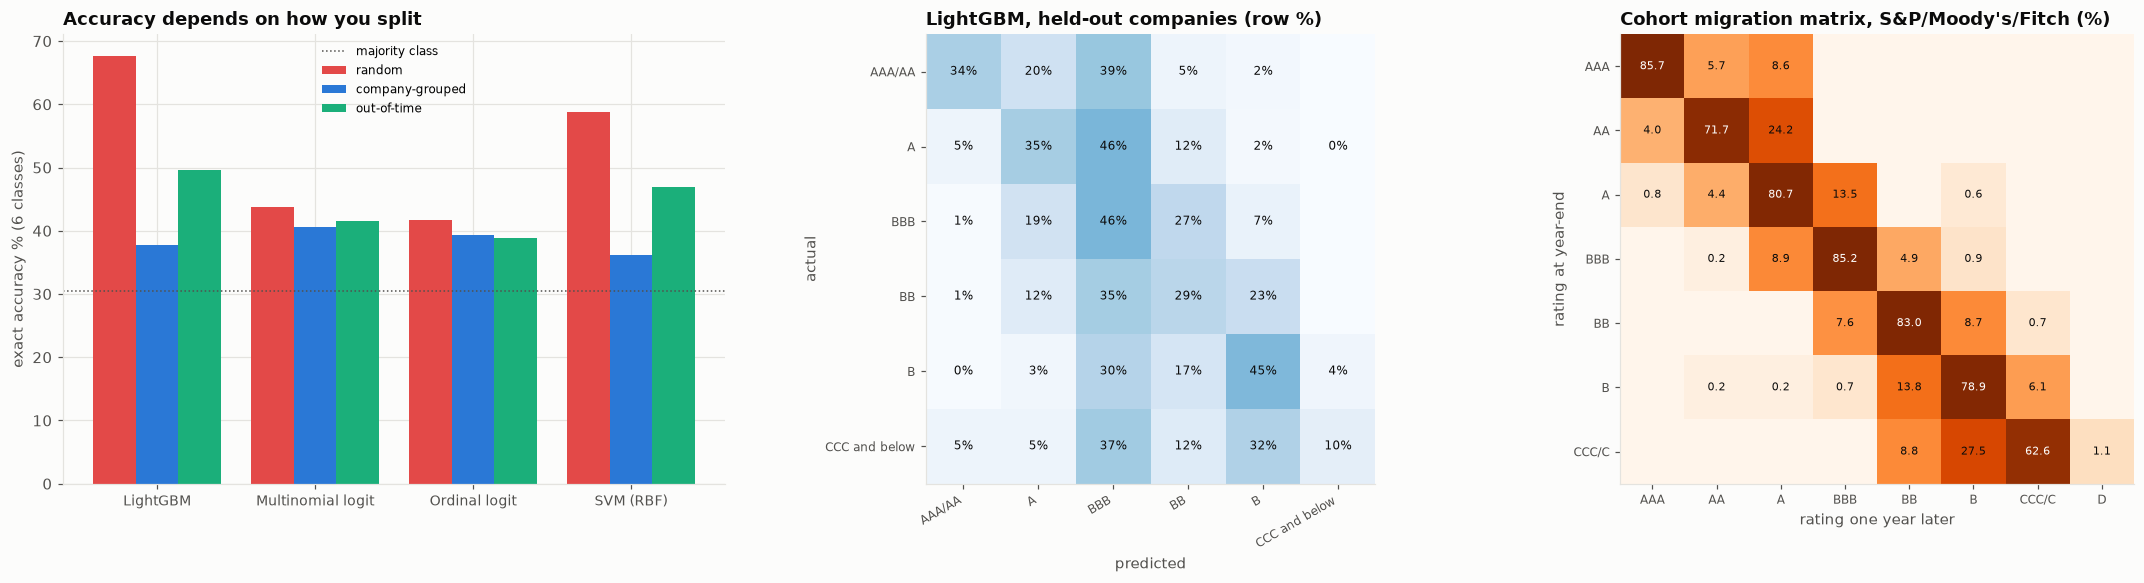

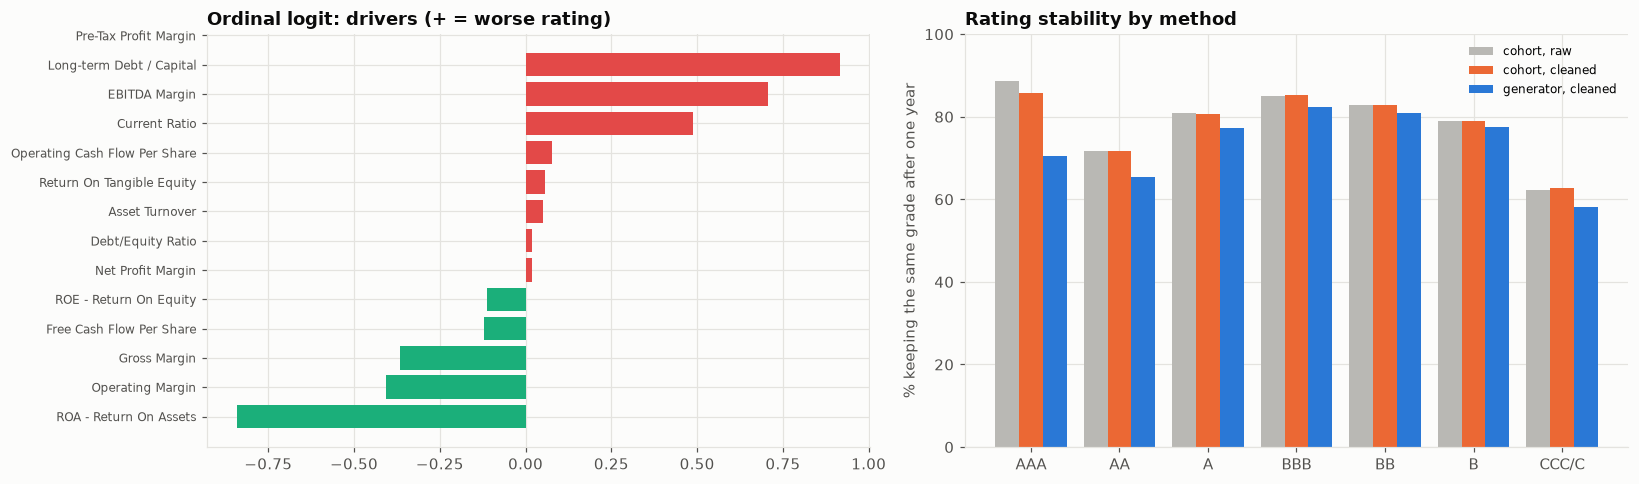

In [9]:
fig, axes = plt.subplots(
    1, 3, figsize=(20, 5.4), gridspec_kw={"width_ratios": [1.1, 1, 1]}
)
ax = axes[0]
res = results["exact accuracy %"].unstack(0)[
    ["random", "company-grouped", "out-of-time"]
]
xi = np.arange(len(res))
for k, (col, c) in enumerate(
    zip(res.columns, [PALETTE[7], PALETTE[0], PALETTE[2]])
):
    ax.bar(xi + (k - 1) * 0.27, res[col], 0.27, color=c, label=col)
ax.axhline(
    base["company-grouped"], color=INK_2, ls=":", lw=1, label="majority class"
)
ax.set_xticks(xi, res.index, fontsize=9)
ax.set_ylabel("exact accuracy % (6 classes)")
ax.set_title("Accuracy depends on how you split")
ax.legend(fontsize=8)
ax = axes[1]
cmn = cm / cm.sum(1, keepdims=True)
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j]:
            ax.text(
                j,
                i,
                f"{cmn[i, j]:.0%}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if cmn[i, j] > 0.5 else INK,
            )
ax.set_xticks(
    range(len(CLASSES)), CLASSES, rotation=30, ha="right", fontsize=8
)
ax.set_yticks(range(len(CLASSES)), CLASSES, fontsize=8)
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
ax.grid(False)
ax.set_title("LightGBM, held-out companies (row %)")
ax = axes[2]
show = coh.reindex(columns=GRADES).fillna(0).to_numpy()
ax.imshow(np.log1p(show), cmap="Oranges")
for i in range(show.shape[0]):
    for j in range(show.shape[1]):
        if show[i, j] >= 0.05:
            ax.text(
                j,
                i,
                f"{show[i, j]:.1f}",
                ha="center",
                va="center",
                fontsize=7.5,
                color="white" if show[i, j] > 50 else INK,
            )
ax.set_xticks(range(len(GRADES)), GRADES, fontsize=8)
ax.set_yticks(range(len(GRADES) - 1), GRADES[:-1], fontsize=8)
ax.set_xlabel("rating one year later")
ax.set_ylabel("rating at year-end")
ax.grid(False)
ax.set_title("Cohort migration matrix, S&P/Moody's/Fitch (%)")
plt.tight_layout()
save_fig(fig, "01_accuracy_confusion_migration")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ax = axes[0]
dr = drivers["ordinal logit β (+ = worse rating)"].sort_values()
ax.barh(
    dr.index,
    dr.values,
    color=[PALETTE[7] if v > 0 else PALETTE[2] for v in dr.values],
)
ax.set_title("Ordinal logit: drivers (+ = worse rating)")
ax.tick_params(axis="y", labelsize=8)
ax = axes[1]
xi = np.arange(len(stab))
ax.bar(
    xi - 0.27,
    stab["cohort (raw) stay %"],
    0.27,
    color="#b9b8b4",
    label="cohort, raw",
)
ax.bar(
    xi,
    stab["cohort (clean) stay %"],
    0.27,
    color=PALETTE[1],
    label="cohort, cleaned",
)
ax.bar(
    xi + 0.27,
    stab["generator (clean) stay %"],
    0.27,
    color=PALETTE[0],
    label="generator, cleaned",
)
ax.set_xticks(xi, stab.index)
ax.set_ylabel("% keeping the same grade after one year")
ax.set_ylim(0, 100)
ax.set_title("Rating stability by method")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "02_drivers_and_stability")
plt.show()

## 8. Reading the results and limitations

7,804 ratings of 678 U.S. listed companies, 2010–2016, predicted in six classes (majority-class accuracy about 30%):

**A random split hides a leak.** With a random 75/25 split, LightGBM gets **68%** of ratings exactly right and 95% within one class, with an investment-grade AUC of 0.95. When whole companies are held out, it falls to **38%** exact and 82% within one class (AUC 0.80).

The gap is the model recognising companies it has already seen, through near-identical ratios across agencies and years. The out-of-time split sits between the two (50%), because the same companies are rated again in 2015–2016. Only the company-grouped number says how a shadow-rating model would perform on a new, unrated counterparty.

**On new companies, the simple models are as good as the flexible ones.** Held-out-company exact accuracy is 39% for the ordinal logit, 41% for the multinomial logit, 36% for the SVM and 38% for LightGBM. The ordinal logit has the best within-one-class accuracy (86%) and the lowest error in classes (0.78). The extra flexibility of the SVM and LightGBM mostly memorises companies.

**About 40% exact is the realistic ceiling from ratios alone.** Agencies also weigh size, business risk, market position, ownership and qualitative judgement, none of which is in the data. Most errors are one class off. The model compresses toward BBB: 30–46% of every true class is predicted as BBB, and the extremes (AAA/AA, CCC and below) are rarely predicted correctly.

For a shadow rating that means an ordinal model plus an analyst override, not a model alone.

**Leverage and profitability drive ratings, as theory says.** Long-term debt / capital is the strongest variable in both models (ordinal β +0.92 per standard deviation toward a worse rating; 12% of LightGBM gain). ROA, gross margin and operating margin push toward better ratings. Two signs need care.

A higher current ratio goes with *worse* ratings: large investment-grade companies run lean working capital, while weaker ones hoard liquidity. The positive EBITDA-margin coefficient, given the operating margin, captures capital intensity (high depreciation), not a real penalty on profits.

**The agencies disagree more than expected.** On ratings within 90 days of each other, S&P and Moody's give the same notch only 36% of the time and are within one notch 68% of the time. Moody's is on average 0.6 notches harsher. Egan-Jones, the investor-paid agency, matches S&P's exact notch only 16% of the time, is half a notch more lenient on average, and differs by three notches or more in 28% of cases.

A model trained on a mix of agencies inherits this noise, which also caps its accuracy.

**Migration matrices look like the published ones, with fewer observations.** The cleaned one-year cohort matrix for S&P, Moody's and Fitch keeps 85% of BBB, 83% of BB, 81% of A and 79% of B in their grade. That is in line with the high-70s to high-80s diagonals of the agencies' own long-run studies.

The cohort AA row (72% stay, 24% to A) reflects the many AA downgrades of 2011–2015, from only 99 observations. Defaults are almost absent (one transition from CCC/C), so default columns cannot be estimated from this sample. In practice they come from agency default studies or from a PD model.

**The generator method changes the matrix in the expected direction.** Counting every rating change and the time at risk lowers the probability of staying in a grade by 1–15 points (AAA 70% vs 86% by cohort). It also gives small positive probabilities to moves never seen year-end to year-end, for example 0.04% default from B. Cohort matrices miss changes that reverse within a year, so they understate rating volatility.

**Data quality matters.** 30% of consecutive S&P/Moody's/Fitch actions change the notch, and 52 actions (1.1%) are three-notch round trips within a year, almost certainly issue ratings mixed with issuer ratings. Removing them changes the AAA row by 3 points. Before such a dataset feeds IFRS 9 staging or a CreditMetrics model, the rating history needs this kind of cleaning, and ideally the agency's issuer-level feed.

**Limitations**

- Ratios come from one filing per rating action; there is no market data (equity volatility, spreads), which the agencies and structural models use.
- 2010–2016 is a benign credit period with very few defaults.
- The six-class target merges notches; notch-level prediction would show lower exact accuracy and the same ordering of models.

In [10]:
results.to_csv(OUT_DIR / "prediction_accuracy_by_split.csv")
drivers.to_csv(OUT_DIR / "rating_drivers.csv")
agree.to_csv(OUT_DIR / "agency_agreement.csv", index=False)
coh.to_csv(OUT_DIR / "migration_matrix_cohort.csv")
gen.to_csv(OUT_DIR / "migration_matrix_generator.csv")
stab.to_csv(OUT_DIR / "rating_stability.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_accuracy_confusion_migration.png, 02_drivers_and_stability.png, agency_agreement.csv, migration_matrix_cohort.csv, migration_matrix_generator.csv, prediction_accuracy_by_split.csv, rating_drivers.csv, rating_stability.csv


## References

### Finance and regulation

- Blume, M. E., Lim, F., & MacKinlay, A. C. (1998). The declining credit quality of U.S. corporate debt: Myth or reality? *The Journal of Finance, 53*(4), 1389–1413. https://doi.org/10.1111/0022-1082.00057
- Jarrow, R. A., Lando, D., & Turnbull, S. M. (1997). A Markov model for the term structure of credit risk spreads. *The Review of Financial Studies, 10*(2), 481–523. https://doi.org/10.1093/rfs/10.2.481
- Lando, D., & Skødeberg, T. M. (2002). Analyzing rating transitions and rating drift with continuous observations. *Journal of Banking & Finance, 26*(2–3), 423–444. https://doi.org/10.1016/S0378-4266(01)00228-X
- Lando, D. (2004). *Credit risk modeling: Theory and applications*. Princeton University Press. https://doi.org/10.1515/9781400829194
- International Accounting Standards Board. (2014). *IFRS 9 Financial instruments*. IFRS Foundation. https://www.ifrs.org/issued-standards/list-of-standards/ifrs-9-financial-instruments/

### Machine learning and deep learning

- McCullagh, P. (1980). Regression models for ordinal data. *Journal of the Royal Statistical Society: Series B, 42*(2), 109–127. https://doi.org/10.1111/j.2517-6161.1980.tb01109.x
- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297. https://doi.org/10.1007/BF00994018
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21. https://doi.org/10.1145/2382577.2382579